# 02 · LSTM captioning model: train and evaluate (Phases 5 and 6)

The **LSTM baseline** (Show and Tell style): the image summary vector from ResNet-50 starts an LSTM, which then writes the caption one word at a time.

| Part | What happens |
|---|---|
| Phase 5 | dataset, model, training with teacher forcing, early stopping, loss curves |
| Phase 6 | greedy and beam search decoding, test-set scores, a nearest-neighbour baseline, good and bad examples, captioning a new photo |

**On Kaggle:** **Add Input → Your Work → Notebooks →** your notebook 01, plus the `adityajn105/flickr8k` dataset (for showing photos). Set **GPU T4** and **Internet: On**, then run all (about 10 minutes).

**Language switch:** set `LANG = "bn"` in the next cell to train the same model on Bangla. Nothing else changes.

## Setup and settings

In [1]:
%pip install -q pycocoevalcap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, math, random, base64, io
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, HTML

LANG = "en"            # "en" = English, "bn" = Bangla

CFG = dict(
    embed_dim=512,     # size of each word vector
    hidden_dim=512,    # size of the LSTM memory
    dropout=0.5,       # randomly switch off 50% of units while training, against overfitting
    batch_size=128,
    lr=4e-4,           # learning rate for Adam
    max_epochs=20,
    patience=3,        # stop when validation loss has not improved for 3 epochs
    grad_clip=5.0,
    beam_size=3,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| language:", LANG, "| settings:", CFG)

device: cpu | language: en | settings: {'embed_dim': 512, 'hidden_dim': 512, 'dropout': 0.5, 'batch_size': 128, 'lr': 0.0004, 'max_epochs': 20, 'patience': 3, 'grad_clip': 5.0, 'beam_size': 3}


## Load the files from notebook 01

In [3]:
ON_KAGGLE = Path("/kaggle/input").exists()
ROOTS = [Path("/kaggle/input")] if ON_KAGGLE else [Path("../data/processed"), Path("../data")]
OUT = Path("/kaggle/working") if ON_KAGGLE else Path("../checkpoints")
OUT.mkdir(parents=True, exist_ok=True)

def find(name, want_dir=False):
    for root in ROOTS:
        if root.exists():
            for dirpath, dirnames, filenames in os.walk(root):
                if (want_dir and name in dirnames) or (not want_dir and name in filenames):
                    return Path(dirpath) / name
    return None

PREP = find(f"vocab_{LANG}.json").parent
IMG_DIR = find("Images", want_dir=True)            # only used to show photos
print("prepared files:", PREP, "| images:", IMG_DIR)

images  = json.load(open(PREP / "images.json", encoding="utf-8"))
vocab   = json.load(open(PREP / f"vocab_{LANG}.json", encoding="utf-8"))
itos, MAX_WORDS = vocab["itos"], vocab["max_words"]
PAD, START, END, UNK = 0, 1, 2, 3
enc     = np.load(PREP / f"encoded_{LANG}.npz")
ids, img_idx, split = enc["ids"], enc["img_idx"], enc["split"]
caps    = pd.read_csv(PREP / "captions_split.csv", encoding="utf-8")
pos     = {name: i for i, name in enumerate(images)}                                  # image name -> feature row
feats   = torch.from_numpy(np.load(PREP / "feats_pooled.npy").astype(np.float32))   # (8091, 2048)

print(f"vocabulary {len(itos)} | captions {ids.shape} | features {tuple(feats.shape)}")
print({s: int((split == s).sum()) for s in ["train", "val", "test"]})

prepared files: ../data/processed | images: ../data/Images
vocabulary 2533 | captions (40455, 22) | features (8091, 2048)
{'train': 30000, 'val': 5000, 'test': 5000}


**Expected:** about 2,500 English words, `captions (40455, 22)`, `features (8091, 2048)`, and 30,000 / 5,000 / 5,000 train / val / test captions.

## Phase 5 · Dataset and DataLoader
One training example = **one image vector + one of its captions**. Each image has 5 captions, so the 6,000 training images give 30,000 examples. The DataLoader shuffles them and groups them into batches of 128.

In [4]:
class CaptionDataset(torch.utils.data.Dataset):
    def __init__(self, which):
        self.rows = np.where(split == which)[0]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, k):
        r = self.rows[k]
        return feats[img_idx[r]], torch.from_numpy(ids[r]).long()

train_dl = torch.utils.data.DataLoader(CaptionDataset("train"), batch_size=CFG["batch_size"], shuffle=True)
val_dl   = torch.utils.data.DataLoader(CaptionDataset("val"),   batch_size=CFG["batch_size"])
x, y = next(iter(train_dl))
print("one batch:", tuple(x.shape), tuple(y.shape))

one batch: (128, 2048) (128, 22)


**Expected:** `one batch: (128, 2048) (128, 22)`: 128 image vectors and 128 captions of 22 word ids each.

## Phase 5 · The model
1. **Image → starting memory:** the 2,048-number image vector is squeezed to 512 numbers and used as the LSTM's initial memory (`h` and `c`). This is how the image "tells" the LSTM what to talk about.
2. **Embedding:** each word id becomes a 512-number vector that the model learns.
3. **LSTM:** reads the words one by one and updates its memory.
4. **Output layer:** turns the memory into a score for every word in the vocabulary; the highest score is the predicted next word.

In [5]:
class LSTMCaptioner(nn.Module):
    def __init__(self, vocab_size, feat_dim=2048, embed_dim=512, hidden_dim=512, dropout=0.5):
        super().__init__()
        self.img_proj = nn.Sequential(nn.Linear(feat_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.init_h = nn.Linear(hidden_dim, hidden_dim)
        self.init_c = nn.Linear(hidden_dim, hidden_dim)
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden_dim, vocab_size)

    def init_state(self, f):                      # image vector -> first LSTM memory
        v = self.img_proj(f)
        return torch.tanh(self.init_h(v)).unsqueeze(0), torch.tanh(self.init_c(v)).unsqueeze(0)

    def forward(self, f, words_in):               # used in training (teacher forcing)
        h, _ = self.lstm(self.drop(self.embed(words_in)), self.init_state(f))
        return self.out(self.drop(h))             # (B, T, vocab) scores

    def step(self, word, state):                  # used when generating: one word at a time
        h, state = self.lstm(self.embed(word).unsqueeze(1), state)
        return self.out(h.squeeze(1)), state

model = LSTMCaptioner(len(itos), embed_dim=CFG["embed_dim"], hidden_dim=CFG["hidden_dim"], dropout=CFG["dropout"]).to(DEVICE)
print(model)
print("trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

LSTMCaptioner(
  (img_proj): Sequential(
    (0): Linear(in_features=2048, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
  )
  (init_h): Linear(in_features=512, out_features=512, bias=True)
  (init_c): Linear(in_features=512, out_features=512, bias=True)
  (embed): Embedding(2533, 512, padding_idx=0)
  (lstm): LSTM(512, 512, batch_first=True)
  (drop): Dropout(p=0.5, inplace=False)
  (out): Linear(in_features=512, out_features=2533, bias=True)
)
trainable parameters: 6,271,973


## Phase 5 · Training
* **Teacher forcing:** the model gets the *correct* previous words as input and must predict the next word. Input = caption without its last token, target = caption without `<start>`.
* **Loss:** cross-entropy, how surprised the model is by the correct next word. `ignore_index=PAD` means padding positions do not count.
* **Adam** updates the weights; **gradient clipping** stops rare huge updates.
* **Validation loss** is checked after every epoch. The best model is saved, and training **stops early** when validation loss has not improved for 3 epochs (the model has started memorising the training captions).

In [6]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

def run_epoch(dl, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for f, y in dl:
            f, y = f.to(DEVICE), y.to(DEVICE)
            logits = model(f, y[:, :-1])                                  # predict word t+1 from words <= t
            loss = criterion(logits.reshape(-1, logits.size(-1)), y[:, 1:].reshape(-1))
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
                optimizer.step()
            total += loss.item() * len(y); n += len(y)
    return total / n

best_path, last_path = OUT / f"lstm_{LANG}_best.pt", OUT / f"lstm_{LANG}_last.pt"
def save(path, epoch, val_loss):
    torch.save({"model": model.state_dict(), "cfg": CFG, "itos": itos, "max_words": MAX_WORDS,
                "lang": LANG, "epoch": epoch, "val_loss": val_loss}, path)

history, best, bad_epochs = [], float("inf"), 0
for epoch in range(1, CFG["max_epochs"] + 1):
    t0 = time.time()
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    history.append({"epoch": epoch, "train_loss": tr, "val_loss": va})
    save(last_path, epoch, va)                                           # checkpoint every epoch
    flag = ""
    if va < best:
        best, bad_epochs, flag = va, 0, "  <- best, saved"
        save(best_path, epoch, va)
    else:
        bad_epochs += 1
    print(f"epoch {epoch:2d} | train {tr:.3f} | val {va:.3f} | {time.time() - t0:4.0f}s{flag}")
    if bad_epochs >= CFG["patience"]:
        print(f"early stopping: no improvement for {CFG['patience']} epochs")
        break
pd.DataFrame(history).to_csv(OUT / f"history_lstm_{LANG}.csv", index=False)

epoch  1 | train 4.555 | val 3.809 |   40s  <- best, saved
epoch  2 | train 3.765 | val 3.510 |   41s  <- best, saved
epoch  3 | train 3.518 | val 3.336 |   38s  <- best, saved
epoch  4 | train 3.352 | val 3.202 |   39s  <- best, saved
epoch  5 | train 3.220 | val 3.104 |   40s  <- best, saved
epoch  6 | train 3.115 | val 3.033 |   40s  <- best, saved
epoch  7 | train 3.032 | val 2.973 |   40s  <- best, saved
epoch  8 | train 2.963 | val 2.929 |   40s  <- best, saved
epoch  9 | train 2.904 | val 2.900 |   40s  <- best, saved
epoch 10 | train 2.853 | val 2.868 |   40s  <- best, saved
epoch 11 | train 2.808 | val 2.847 |   40s  <- best, saved
epoch 12 | train 2.765 | val 2.835 |   40s  <- best, saved
epoch 13 | train 2.732 | val 2.815 |   40s  <- best, saved
epoch 14 | train 2.700 | val 2.792 |   40s  <- best, saved
epoch 15 | train 2.669 | val 2.779 |   41s  <- best, saved
epoch 16 | train 2.642 | val 2.771 |   39s  <- best, saved
epoch 17 | train 2.616 | val 2.767 |   41s  <- best, sav

**Expected:** both losses fall during the first epochs. Validation loss reaches its lowest point after roughly 5 to 10 epochs, then starts rising while training loss keeps falling. That gap is overfitting, and early stopping ends training there.

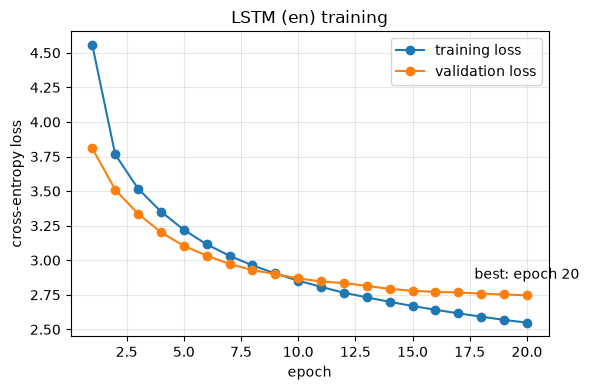

In [7]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(h.epoch, h.train_loss, "o-", label="training loss")
ax.plot(h.epoch, h.val_loss, "o-", label="validation loss")
b = h.loc[h.val_loss.idxmin()]
ax.annotate(f"best: epoch {int(b.epoch)}", (b.epoch, b.val_loss), textcoords="offset points", xytext=(0, 12), ha="center")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.set_title(f"LSTM ({LANG}) training")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(OUT / f"loss_lstm_{LANG}.png", dpi=200); plt.show()

## Phase 6 · Generating captions
After training there is no correct caption to copy from, so the model feeds its **own** previous word back in, starting from `<start>` until it writes `<end>`.
* **Greedy:** always take the single most likely next word. Fast, but one early mistake cannot be undone.
* **Beam search (k = 3):** keep the 3 best partial captions at every step and pick the best complete one at the end. Usually a little better.

In [8]:
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["model"]); model.eval()
print("loaded best model from epoch", ckpt["epoch"])

def to_words(seq):
    out = []
    for i in seq:
        if i == END: break
        if i not in (PAD, START): out.append(itos[i])
    return out

BLOCKED = [PAD, START, UNK]

@torch.no_grad()
def greedy(f_batch, max_len=MAX_WORDS + 1):
    state = model.init_state(f_batch.to(DEVICE))
    word = torch.full((len(f_batch),), START, device=DEVICE)
    seqs = []
    for _ in range(max_len):
        logits, state = model.step(word, state)
        logits[:, BLOCKED] = -float("inf")           # never write <pad>, <start> or <unk>
        word = logits.argmax(-1)
        seqs.append(word)
    return [to_words(s) for s in torch.stack(seqs, 1).tolist()]

@torch.no_grad()
def beam_search(f, k=CFG["beam_size"], max_len=MAX_WORDS + 1):
    h, c = model.init_state(f.unsqueeze(0).to(DEVICE))
    beams = [([START], 0.0, h, c)]                     # (words so far, total log-probability, memory)
    done = []
    for _ in range(max_len):
        words = torch.tensor([b[0][-1] for b in beams], device=DEVICE)
        hs, cs = torch.cat([b[2] for b in beams], 1), torch.cat([b[3] for b in beams], 1)
        logits, (h2, c2) = model.step(words, (hs, cs))
        logits[:, BLOCKED] = -float("inf")
        top_lp, top_w = F.log_softmax(logits, -1).topk(k, -1)
        cand = []
        for bi, (seq, score, _, _) in enumerate(beams):
            for j in range(k):
                w, s = top_w[bi, j].item(), score + top_lp[bi, j].item()
                if w == END:
                    done.append((seq, s))
                else:
                    cand.append((seq + [w], s, h2[:, bi:bi + 1], c2[:, bi:bi + 1]))
        if len(done) >= k or not cand:
            break
        beams = sorted(cand, key=lambda b: b[1], reverse=True)[:k]
    if not done:
        done = [(b[0], b[1]) for b in beams]
    best_seq = max(done, key=lambda d: d[1] / len(d[0]))[0]     # length-normalised so short captions are not favoured
    return to_words(best_seq)

test_imgs = sorted(set(caps[caps.split == "test"].image))
X_test = feats[[pos[i] for i in test_imgs]]
for name, f in list(zip(test_imgs, X_test))[:3]:
    print(name)
    print("  greedy:", " ".join(greedy(f.unsqueeze(0))[0]))
    print("  beam  :", " ".join(beam_search(f)))
    print("  human :", caps[(caps.image == name)][f"{LANG}_tok"].iloc[0])

loaded best model from epoch 20
1056338697_4f7d7ce270.jpg
  greedy: a young girl in a red dress is holding a sign
  beam  : a young girl in a red dress is standing on a sidewalk
  human : a blond woman in a blue shirt appears to wait for a ride
106490881_5a2dd9b7bd.jpg
  greedy: a young boy in a blue shirt is playing in the water
  beam  : a young boy wearing a blue shirt is playing in the water
  human : a boy in his blue swim shorts at the beach
1082379191_ec1e53f996.jpg
  greedy: a man in a blue shirt is sitting on a rock overlooking a lake
  beam  : a man and a woman are sitting on a bench
  human : a lady and a man with no shirt sit on a dock


## Phase 6 · Scores on the 1,000 test images
Each generated caption is compared with the **5 human captions** of the same photo:
* **BLEU-1 to BLEU-4:** share of 1-, 2-, 3- and 4-word sequences that also appear in the human captions.
* **METEOR** (English only): word matching that also accepts stems and synonyms.
* **ROUGE-L:** the longest shared word sequence.
* **CIDEr:** agreement with the consensus of all 5 human captions, rewarding informative words. Our main metric.

**Nearest-neighbour baseline:** no learning at all. For each test photo, find the most similar *training* photo (by ResNet-50 features) and copy its caption. A real model should beat this.

In [9]:
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

refs = {i: caps[caps.image == i][f"{LANG}_tok"].tolist() for i in test_imgs}

class NltkMeteor:                                         # fallback when Java is missing
    def __init__(self):
        import nltk
        from nltk.translate.meteor_score import meteor_score
        for pkg in ["wordnet", "omw-1.4"]:
            nltk.download(pkg, quiet=True)
        self.f = meteor_score
        self.f([["a", "dog"]], ["a", "dog"])
    def compute_score(self, gts, res):
        s = [self.f([r.split() for r in gts[k]], res[k][0].split()) for k in gts]
        return float(np.mean(s)), s

def meteor_scorer():
    if LANG != "en":
        return None                                          # METEOR's synonym matching is English only
    try:
        from pycocoevalcap.meteor.meteor import Meteor       # official version, needs Java
        m = Meteor(); m.compute_score({"a": ["a dog"]}, {"a": ["a dog"]}); print("METEOR: official (Java)"); return m
    except Exception:
        pass
    try:
        m = NltkMeteor(); print("METEOR: NLTK version (Java not found)"); return m
    except Exception as e:
        print("METEOR unavailable:", type(e).__name__, "- reported as NaN"); return None
METEOR = meteor_scorer()

def score(hyps):
    res = {i: [" ".join(hyps[i]) if hyps[i] else "a"] for i in test_imgs}
    gts = {i: refs[i] for i in test_imgs}
    b, _ = Bleu(4).compute_score(gts, res, verbose=0)
    r, _ = Rouge().compute_score(gts, res)
    c, per_img = Cider().compute_score(gts, res)
    m = METEOR.compute_score(gts, res)[0] if METEOR else float("nan")
    row = {"BLEU-1": b[0], "BLEU-2": b[1], "BLEU-3": b[2], "BLEU-4": b[3], "METEOR": m, "ROUGE-L": r, "CIDEr": c}
    return row, dict(zip(sorted(gts), per_img))

# nearest-neighbour baseline
train_imgs = sorted(set(caps[caps.split == "train"].image))
X_train = feats[[pos[i] for i in train_imgs]]
sim = F.normalize(X_test, dim=1) @ F.normalize(X_train, dim=1).T
nn_hyp = {}
for t, j in zip(test_imgs, sim.argmax(1).tolist()):
    nn_hyp[t] = caps[(caps.image == train_imgs[j]) & (caps.cap_idx == 0)][f"{LANG}_tok"].iloc[0].split()

t0 = time.time()
greedy_hyp = {}
for s in range(0, len(test_imgs), 256):
    for name, words in zip(test_imgs[s:s + 256], greedy(X_test[s:s + 256])):
        greedy_hyp[name] = words
beam_hyp = {name: beam_search(f) for name, f in zip(test_imgs, X_test)}
print(f"captions generated in {time.time() - t0:.0f}s")

results, per_image = {}, {}
for name, hyp in [("Nearest neighbour", nn_hyp), ("LSTM greedy", greedy_hyp), (f"LSTM beam {CFG['beam_size']}", beam_hyp)]:
    results[name], per_image[name] = score(hyp)
table = pd.DataFrame(results).T.round(3)
table.to_csv(OUT / f"results_lstm_{LANG}.csv")
display(table)

METEOR: official (Java)
captions generated in 7s


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr
Nearest neighbour,0.437,0.252,0.145,0.084,0.150,0.344,0.246
LSTM greedy,0.569,0.387,0.252,0.163,0.188,0.436,0.411
LSTM beam 3,0.609,0.421,0.286,0.196,0.193,0.449,0.472


**How to read it:** higher is better everywhere. For English on Flickr8k, published LSTM models of this kind report roughly BLEU-1 around 0.6 and BLEU-4 around 0.2. Your numbers may be somewhat lower; what matters for the 50% demo is that the LSTM clearly beats the nearest-neighbour baseline, especially on CIDEr.

## Phase 6 · Good and bad examples
Sorted by each caption's own CIDEr score. Looking at failures is how you find out *what* the model gets wrong (wrong object, wrong count, generic phrases).

,model: a black and white dog is running on the beachhuman: a black and white dog is running on the beachCIDEr 4.31
,model: two white dogs run through the grasshuman: the two white dogs are playing in a fieldCIDEr 4.10
,model: a white dog is running through the waterhuman: a pale colored dog runs through a body of waterCIDEr 3.51
,model: a white dog is running through the snowhuman: a dog is playing in the deep snowCIDEr 3.40
,model: a brown dog is jumping over a hurdlehuman: a brown dog jumping over a blue and yellow stickCIDEr 3.08

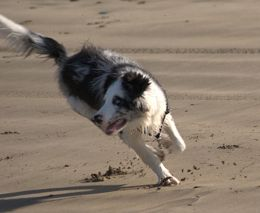
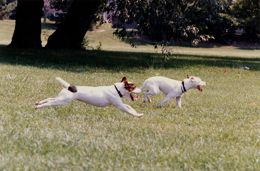
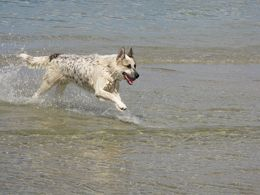
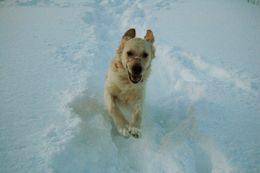
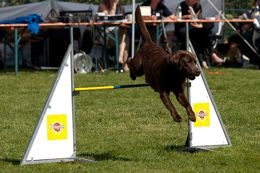

,model: two girls are sitting on a wooden benchhuman: a little blonde girl is standing in front of a water fountainCIDEr 0.00
,model: two people are sitting on a dockhuman: a few boats ride in the water in front of a city skylineCIDEr 0.00
,model: a young boy wearing a blue shirt is playing with a guitarhuman: the three children are in a cageCIDEr 0.00
,model: a black and brown dog is running through a grassy fieldhuman: two dobermans fighting or playing together on a lawnCIDEr 0.00
,model: a group of people are standing in front of a buildinghuman: a girl with pink streaked hair and fur uggs looks back while the girl walking next to her looks at herCIDEr 0.00

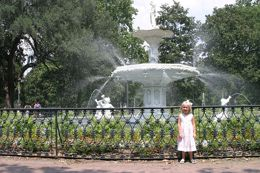
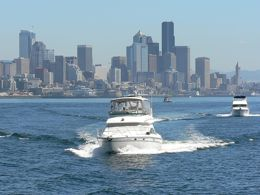
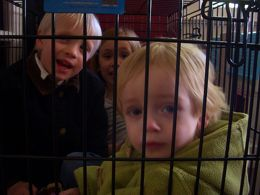
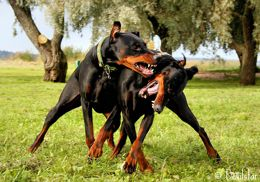
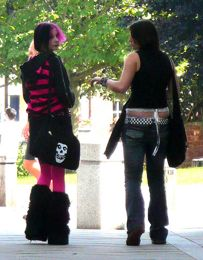

In [10]:
def thumb(name, w=260):
    if IMG_DIR is None or not (IMG_DIR / name).exists():
        return ""
    from PIL import Image
    with Image.open(IMG_DIR / name) as im:
        im = im.convert("RGB"); im.thumbnail((w, w))
        buf = io.BytesIO(); im.save(buf, "JPEG", quality=80)
    return f"<img src='data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}'>"

key = f"LSTM beam {CFG['beam_size']}"
ranked = sorted(per_image[key].items(), key=lambda kv: kv[1], reverse=True)
def gallery(title, items):
    rows = "".join(
        f"<tr><td style='padding:6px'>{thumb(n)}</td><td style='padding:6px;text-align:left;vertical-align:top'>"
        f"<b>model:</b> {' '.join(beam_hyp[n])}<br><b>human:</b> {refs[n][0]}<br><small>CIDEr {s:.2f}</small></td></tr>"
        for n, s in items)
    display(HTML(f"<h4>{title}</h4><table>{rows}</table>"))
gallery("5 best captions", ranked[:5])
gallery("5 worst captions", ranked[-5:])
pd.DataFrame([{"image": n, "cider": s, "model": " ".join(beam_hyp[n]), "human": refs[n][0]} for n, s in ranked]) \
  .to_csv(OUT / f"examples_lstm_{LANG}.csv", index=False)

## Demo · Caption any photo
This is the full path the web app will use: photo → ResNet-50 → LSTM → words. On Kaggle, upload your own photo with **Add Input → Upload** or use any test image path.


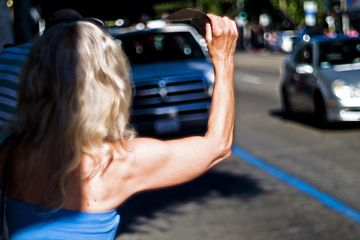

caption: a young girl in a red dress is standing on a sidewalk


In [11]:
import torchvision
from torchvision import transforms
from PIL import Image

cnn = nn.Sequential(*list(torchvision.models.resnet50(
    weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1).children())[:-2]).to(DEVICE).eval()
tfm = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                          transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def caption_photo(path):
    with Image.open(path) as im:
        x = tfm(im.convert("RGB")).unsqueeze(0).to(DEVICE)
    f = cnn(x).flatten(2).mean(-1).squeeze(0).cpu()              # same pooled vector as notebook 01
    return " ".join(beam_search(f))

demo = IMG_DIR / test_imgs[0] if IMG_DIR else None
if demo and demo.exists():
    display(HTML(thumb(demo.name, 360)))
    print("caption:", caption_photo(demo))

## Saved files
`lstm_{LANG}_best.pt` (the trained model with its vocabulary), `history_lstm_{LANG}.csv`, `loss_lstm_{LANG}.png`, `results_lstm_{LANG}.csv`, `examples_lstm_{LANG}.csv`. Download them from the **Output** panel and keep them in your repo's `checkpoints/` and `docs/` folders.

### For the 50% viva, everyone should be able to explain
1. What teacher forcing is, and why generation cannot use it.
2. Why padding is ignored in the loss.
3. What the gap between training and validation loss means, and what early stopping does about it.
4. The difference between greedy and beam search.
5. Why we compare with a nearest-neighbour baseline, and what CIDEr measures.